<a href="https://colab.research.google.com/github/Rony2019-2023/secure-cxr-detection-gbm/blob/main/notebooks/Naive%20Bayes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image, ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = True

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_sample_weight

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    average_precision_score,
    roc_curve,
    precision_recall_curve
)

# Naive Bayes imports
from sklearn.naive_bayes import GaussianNB

print("All libraries imported successfully!")


All libraries imported successfully!


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
DATA_DIR = "/content/drive/MyDrive/Project/Mydataset/FullData"

CLASS_FOLDERS = {
    "Covid-19": 1,
    "Normal": 0,
    "Viral pneumonia": 0
}

if not os.path.isdir(DATA_DIR):
    raise FileNotFoundError(
        f"Dataset folder not found: {DATA_DIR}"
    )

for folder_name in CLASS_FOLDERS:
    folder_path = os.path.join(DATA_DIR, folder_name)

    if not os.path.isdir(folder_path):
        raise FileNotFoundError(
            f"Folder not found: {folder_path}"
        )

    print(f"{folder_name}: Folder found")

print("\nAll dataset folders verified!")

Covid-19: Folder found
Normal: Folder found
Viral pneumonia: Folder found

All dataset folders verified!


In [ ]:
VALID_EXTENSIONS = (
    ".png", ".jpg", ".jpeg", ".bmp", ".webp"
)

X_list = []
y_list = []
file_paths = []

for folder_name, label in CLASS_FOLDERS.items():

    folder_path = os.path.join(DATA_DIR, folder_name)

    files = [
        os.path.join(folder_path, filename)
        for filename in os.listdir(folder_path)
        if filename.lower().endswith(VALID_EXTENSIONS)
    ]

    print(f"{folder_name}: {len(files)} images")

    for file_path in files:
        try:
            with Image.open(file_path) as img:
                img = img.convert("L")
                img = img.resize((224, 224))

                image_array = np.asarray(
                    img, dtype=np.float32
                ) / 255.0

                X_list.append(image_array.flatten())
                y_list.append(label)
                file_paths.append(file_path)

        except Exception as error:
            print(
                "Skipping unreadable image:",
                file_path,
                error
            )

X = np.asarray(X_list, dtype=np.float32)
y = np.asarray(y_list, dtype=np.int32)
file_paths = np.asarray(file_paths)

print("\nDataset loaded successfully!")
print("Feature matrix shape:", X.shape)
print("Total images:", len(y))
print("COVID-19 images:", int(np.sum(y == 1)))
print("Non-COVID images:", int(np.sum(y == 0)))

if len(X) == 0 or len(np.unique(y)) != 2:
    raise ValueError(
        "Please ensure the dataset contains readable images from both classes."
    )

Covid-19: 3618 images
Normal: 2038 images
Viral pneumonia: 1345 images

Dataset loaded successfully!
Feature matrix shape: (7001, 50176)
Total images: 7001
COVID-19 images: 3618
Non-COVID images: 3383


In [ ]:
# Split dataset into training and testing sets
X_train, X_test, y_train, y_test, paths_train, paths_test = train_test_split(
    X,
    y,
    file_paths,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Print training and testing image counts
print("Training images:", len(X_train))
print("Testing images:", len(X_test))

# Print training class distribution
print("\nTraining class distribution:")
print("COVID-19:", int(np.sum(y_train == 1)))
print("Non-COVID:", int(np.sum(y_train == 0)))

# Print testing class distribution
print("\nTesting class distribution:")
print("COVID-19:", int(np.sum(y_test == 1)))
print("Non-COVID:", int(np.sum(y_test == 0)))

Training images: 5600
Testing images: 1401

Training class distribution:
COVID-19: 2894
Non-COVID: 2706

Testing class distribution:
COVID-19: 724
Non-COVID: 677


In [ ]:

# ============================================================
# Initialize Gaussian Naive Bayes Classifier
# ============================================================

from sklearn.naive_bayes import GaussianNB

# Convert input data to NumPy arrays
X_train_nb = np.asarray(X_train, dtype=np.float32)
X_test_nb = np.asarray(X_test, dtype=np.float32)

# Flatten image data if it has more than 2 dimensions
if X_train_nb.ndim > 2:
    X_train_nb = X_train_nb.reshape(
        X_train_nb.shape[0], -1
    )
    X_test_nb = X_test_nb.reshape(
        X_test_nb.shape[0], -1
    )

# Normalize pixel values if they are in the 0-255 range
if X_train_nb.max() > 1.0:
    X_train_nb /= 255.0
    X_test_nb /= 255.0

# Initialize Gaussian Naive Bayes model
model = GaussianNB()

# ============================================================
# Measure Training Time
# ============================================================

start_time = time.perf_counter()

model.fit(
    X_train_nb,
    np.asarray(y_train).ravel()
)

training_time = time.perf_counter() - start_time

print(
    f"Training completed in {training_time:.2f} seconds"
)

# ============================================================
# Measure Testing Time
# ============================================================

test_start_time = time.perf_counter()

y_pred = model.predict(X_test_nb)
y_prob = model.predict_proba(X_test_nb)[:, 1]

testing_time = time.perf_counter() - test_start_time

print(f"Testing Time: {testing_time:.4f} seconds")
print(f"Test images: {len(X_test_nb)}")

print(
    "Average prediction time per image:",
    f"{testing_time / len(X_test_nb):.6f} seconds"
)


Training completed in 1.40 seconds
Testing Time: 2.0103 seconds
Test images: 1401
Average prediction time per image: 0.001435 seconds


In [ ]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    classification_report
)
import pandas as pd

# ==================== PERFORMANCE METRICS ====================

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred, zero_division=0
)

sensitivity = recall_score(
    y_test, y_pred, zero_division=0
)

f1 = f1_score(
    y_test, y_pred, zero_division=0
)

# ==================== CONFUSION MATRIX ====================

cm = confusion_matrix(
    y_test, y_pred, labels=[0, 1]
)

tn, fp, fn, tp = cm.ravel()

# ==================== SPECIFICITY ====================

specificity = (
    tn / (tn + fp)
    if (tn + fp) > 0
    else 0.0
)

# ==================== AUC METRICS ====================

roc_auc = roc_auc_score(y_test, y_prob)

pr_auc = average_precision_score(
    y_test, y_prob
)

# ==================== RESULTS TABLE ====================

results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Sensitivity (Recall)",
        "Specificity",
        "F1-score",
        "ROC-AUC",
        "PR-AUC (Average Precision)",
        "Training Time (seconds)",
        "Testing Time (seconds)",
        "Average Prediction Time Per Image (seconds)"
    ],
    "Value": [
        accuracy,
        precision,
        sensitivity,
        specificity,
        f1,
        roc_auc,
        pr_auc,
        training_time,
        testing_time,
        testing_time / len(X_test_nb)
    ]
})

print("\n========== NAIVE BAYES RESULTS ==========")
print(results.to_string(index=False))

# ==================== CONFUSION MATRIX VALUES ====================

print("\nNaive Bayes Confusion Matrix:")
print(cm)

print(f"TN = {tn}")
print(f"FP = {fp}")
print(f"FN = {fn}")
print(f"TP = {tp}")

# ==================== CLASSIFICATION REPORT ====================

print("\nNaive Bayes Classification Report:")

print(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["Non-COVID", "COVID-19"],
        zero_division=0
    )
)



========== NAIVE BAYES RESULTS ==========
                                     Metric    Value
                                   Accuracy 0.840828
                                  Precision 0.812734
                       Sensitivity (Recall) 0.899171
                                Specificity 0.778434
                                   F1-score 0.853770
                                    ROC-AUC 0.844496
                 PR-AUC (Average Precision) 0.787390
                    Training Time (seconds) 1.400782
                     Testing Time (seconds) 2.010343
Average Prediction Time Per Image (seconds) 0.001435

Naive Bayes Confusion Matrix:
[[527 150]
 [ 73 651]]
TN = 527
FP = 150
FN = 73
TP = 651

Naive Bayes Classification Report:
              precision    recall  f1-score   support

   Non-COVID       0.88      0.78      0.83       677
    COVID-19       0.81      0.90      0.85       724

    accuracy                           0.84      1401
   macro avg       0.85      0.

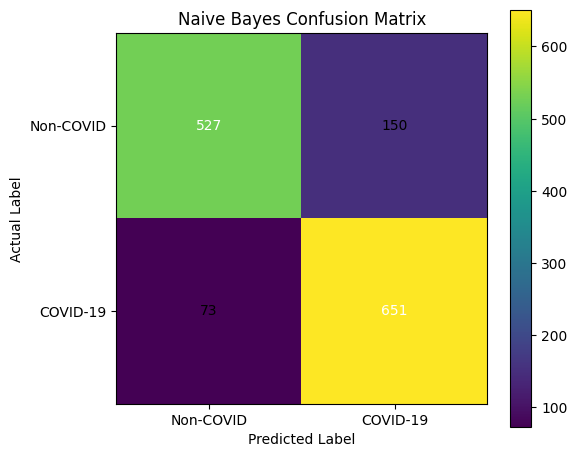

TN = 527
FP = 150
FN = 73
TP = 651


In [ ]:

plt.figure(figsize=(6, 5))
plt.imshow(cm, interpolation="nearest")
plt.title("Naive Bayes Confusion Matrix")
plt.colorbar()

plt.xticks([0, 1], ["Non-COVID", "COVID-19"])
plt.yticks([0, 1], ["Non-COVID", "COVID-19"])

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

threshold = cm.max() / 2 if cm.max() > 0 else 0

for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            str(cm[i, j]),
            ha="center",
            va="center",
            color=(
                "white" if cm[i, j] > threshold
                else "black"
            )
        )

plt.tight_layout()
plt.show()

print(f"TN = {tn}")
print(f"FP = {fp}")
print(f"FN = {fn}")
print(f"TP = {tp}")


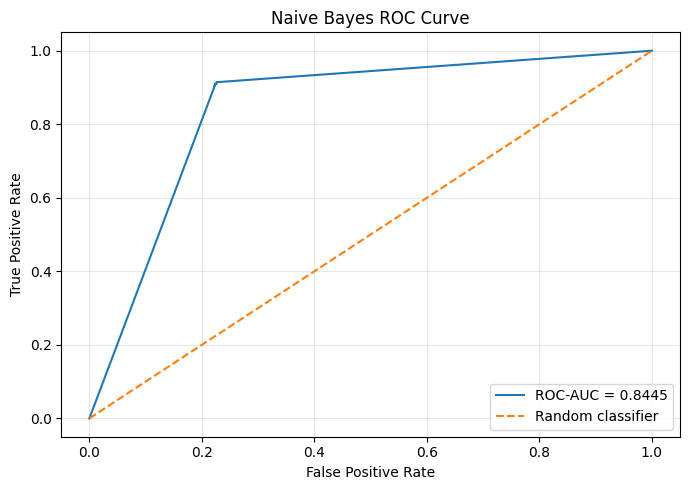

In [ ]:

fpr, tpr, thresholds = roc_curve(y_test, y_prob)

# Calculate ROC-AUC for Logistic Regression
roc_auc = roc_auc_score(y_test, y_prob)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"ROC-AUC = {roc_auc:.4f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    "--",
    label="Random classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Naive Bayes ROC Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


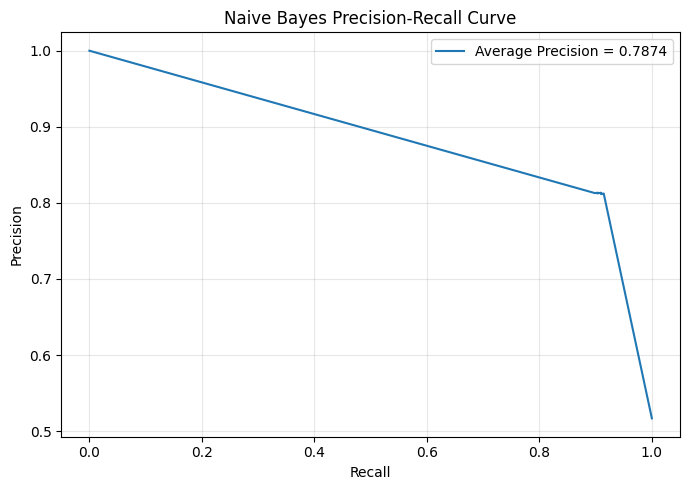

In [ ]:

# Calculate Precision-Recall curve for Logistic Regression
pr_precision, pr_recall, pr_thresholds = (
    precision_recall_curve(y_test, y_prob)
)

# Calculate Average Precision
pr_auc = average_precision_score(y_test, y_prob)

plt.figure(figsize=(7, 5))

plt.plot(
    pr_recall,
    pr_precision,
    label=f"Average Precision = {pr_auc:.4f}"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Naive Bayes Precision-Recall Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:
# ============================================================
# STEP 12: Save Naive Bayes metrics and predictions to Google Drive
# ============================================================

RESULT_DIR = "/content/drive/MyDrive/Project/Results"

os.makedirs(RESULT_DIR, exist_ok=True)

# Save evaluation metrics
results.to_csv(
    os.path.join(RESULT_DIR, "naive_bayes_metrics.csv"),
    index=False
)

# Save test predictions
predictions = pd.DataFrame({
    "Image_Path": paths_test,
    "True_Label": y_test,
    "Predicted_Label": y_pred,
    "COVID_Probability": y_prob
})

predictions.to_csv(
    os.path.join(RESULT_DIR, "naive_bayes_test_predictions.csv"),
    index=False
)

print("Naive Bayes results saved successfully!")
print("Google Drive folder:", RESULT_DIR)


# ============================================================
# STEP 13: Print individual Naive Bayes results
# ============================================================

print("\n========== NAIVE BAYES FINAL METRICS ==========")

print("Precision:", precision)
print("Recall / Sensitivity:", sensitivity)
print("F1 Score:", f1)
print("Specificity:", specificity)
print("Accuracy:", accuracy)
print("ROC-AUC:", roc_auc)
print("PR-AUC:", pr_auc)

print("Training Time:", training_time, "seconds")
print("Testing Time:", testing_time, "seconds")

print(
    "Average Prediction Time Per Image:",
    testing_time / len(X_test),
    "seconds"
)




Naive Bayes results saved successfully!
Google Drive folder: /content/drive/MyDrive/Project/Results

========== NAIVE BAYES FINAL METRICS ==========
Precision: 0.8127340823970037
Recall / Sensitivity: 0.899171270718232
F1 Score: 0.8537704918032787
Specificity: 0.7784342688330872
Accuracy: 0.8408279800142755
ROC-AUC: 0.8444959481625958
PR-AUC: 0.7873897311996295
Training Time: 1.400781746000007 seconds
Testing Time: 2.010343476999992 seconds
Average Prediction Time Per Image: 0.0014349346730906439 seconds
